# Stage 9: Dynamic selection after reranking

**Question:** after MiniLM reranks the top 30 fused candidates, should we keep a fixed number (top 5 or top 10), or
keep however many clear a score cutoff?

**Rules compared**, all applied to the same reranked list of 30 candidates per question:
- **fixed top 5** (the app's current setting) and **fixed top 10**;
- **dynamic (absolute cutoff):** keep every candidate whose cross-encoder score is ≥ the cutoff, then clamp the count
  to 3–15 (fewer than 3 pass → take the top 3; more than 15 → take the top 15);
- **dynamic (relative):** keep candidates within X of that question's top score, same 3–15 clamp. A side check.

**How:** each question's 30 fused candidates are scored by MiniLM once and the scores cached. Every rule is then just
a choice of how many of the reranked candidates to keep, so the whole sweep runs from the cache without touching the
models again. The models load once (nomic ≈ 1.9 GB, MiniLM ≈ 0.1 GB).

**Metrics per rule**, on the 40-question eval set (`evals/handbook_eval.jsonl`, scored as in notebook 08):
- **chunk recall**: `chunk_recall` with k = the number kept, averaged over questions;
- **all chunks found**: share of questions with every expected chunk kept;
- **mean / median items kept**;
- **mean tokens passed on**: `count_tokens` summed over the kept items' text. This is the cost side: more items make
  a bigger prompt for the answering model.

**Model scoring cost is the same for every rule.** All of them rerank the same 30 candidates, so MiniLM time per
question doesn't change. The rules differ only in how much text they pass on.

**Tuning and overfitting.** The cutoff is tuned on the same 40 questions it is scored on, which flatters it. So the
notebook also reports leave-one-out and 5-fold cross-validated estimates: the cutoff is chosen on the training
questions only, with the same rule, and scored on the held-out ones.

In [1]:
import sys
from pathlib import Path

# Use this worktree's copy of the package, not the editable install from the main repo.
WORKTREE_SRC = Path.cwd().resolve().parent / "src"
sys.path.insert(0, str(WORKTREE_SRC))

import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import handbook_qa
from handbook_qa import evaluation as ev
from handbook_qa.config import ROOT, load_settings
from handbook_qa.retrieval import Reranker, Retriever
from handbook_qa.tokens import count_tokens

# Check the package is the worktree copy
print("handbook_qa from:", handbook_qa.__file__)
assert Path(handbook_qa.__file__).resolve().is_relative_to(WORKTREE_SRC.resolve())
pd.set_option("display.max_colwidth", 90)

handbook_qa from: C:\Users\shaba\Documents\extra project\paradigm_assessment\.claude\worktrees\agent-a5fcabd5366536ab4\src\handbook_qa\__init__.py


## Load each model once

The first stage (nomic embeddings + BM25 + RRF) is built with reranking off; MiniLM is loaded separately and called
directly on the 30 fused candidates, exactly as `Retriever.search(..., rerank=True)` does.

In [2]:
settings = load_settings()
r = settings.retrieval
retriever = Retriever.from_settings(replace(settings, retrieval=replace(r, rerank=False)))  # nomic, loaded once
reranker = Reranker(r.rerank_model, settings.embed.model_cache, settings.embed.threads)        # MiniLM, loaded once
# Load questions and resolve the answer key
questions = ev.load_eval_set(ROOT / "evals" / "handbook_eval.jsonl")
problems = ev.resolve(questions, retriever.items)
print(f"{len(questions)} questions; reranker {r.rerank_model}; candidates reranked: {r.rerank_candidates}")
print("answer-key problems:", problems or "none")

C:\Users\shaba\Documents\extra project\paradigm_assessment\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


40 questions; reranker Xenova/ms-marco-MiniLM-L-6-v2; candidates reranked: 30
answer-key problems: none


## Score the 30 candidates per question, once

One row per (question, candidate): its fused rank, MiniLM score and token count. Everything below reads this cache.

In [3]:
rows, seconds = [], []
for q in questions:
    # Fetch fused top 30 and score with MiniLM
    started = time.perf_counter()
    hits = retriever.search(q.question, k=r.rerank_candidates, rerank=False)  # top 30 fused, in fused order
    scores = reranker.score(q.question, [hit.item.text for hit in hits])
    seconds.append(time.perf_counter() - started)
    # Append one row per candidate
    for hit, score in zip(hits, scores):
        rows.append({"id": q.id, "type": q.type, "fused rank": hit.fused_rank, "item": hit.item.id,
                     "kind": hit.item.kind, "score": float(score), "tokens": count_tokens(hit.item.text)})
# Cache table and timing summary
cache = pd.DataFrame(rows)
print(f"{len(cache)} cached scores; first stage + MiniLM per question: median {np.median(seconds):.2f} s, "
      f"max {max(seconds):.2f} s (the same for every rule below)")
cache.head()

1200 cached scores; first stage + MiniLM per question: median 3.25 s, max 3.50 s (the same for every rule below)


,id,type,fused rank,item,kind,score,tokens
0,A-01,existing,1,img-p0041-x258,image,2.723244,240
1,A-01,existing,2,company/communication#06,chunk,1.455724,733
2,A-01,existing,3,company/communication#11,chunk,-0.301182,459
3,A-01,existing,4,growth/sales/communications-templates-incidents#01,chunk,0.843778,568
4,A-01,existing,5,company/security#03,chunk,-1.763221,705


Arrange the cache as arrays. Within each question candidates are sorted by MiniLM score, best first; ties keep the
fused order, as in `Retriever.search`. A rule then only decides **n**, how many of these to keep, so recall and tokens
for every possible n are tabulated once:
- `RECALL[q, n]` = `chunk_recall(reranked ids, question, k=n)`;
- `TOKENS[q, n]` = tokens in the first n items.

In [4]:
# Question lookup, ids and types
by_id = {q.id: q for q in questions}
IDS = list(dict.fromkeys(cache["id"]))
TYPES = np.array([by_id[i].type for i in IDS])
N_CAND = r.rerank_candidates
# Candidates sorted by score per question
ranked = {i: g.sort_values("score", ascending=False, kind="stable") for i, g in cache.groupby("id", sort=False)}
SCORES = np.stack([ranked[i]["score"].to_numpy() for i in IDS])  # (40, 30), each row descending
# Recall for every possible n
RECALL = np.array([[ev.chunk_recall(ranked[i]["item"].tolist(), by_id[i], n) for n in range(N_CAND + 1)] for i in IDS])
# Cumulative tokens for the first n items
TOKENS = np.stack([np.concatenate([[0], np.cumsum(ranked[i]["tokens"].to_numpy())]) for i in IDS])
ROWS = np.arange(len(IDS))

# Report recall ceiling and token sizes
print("recall ceiling if all 30 were kept:", round(RECALL[:, N_CAND].mean(), 3),
      "| at 15 (the clamp's maximum):", round(RECALL[:, 15].mean(), 3))
print("tokens per candidate: median", int(cache["tokens"].median()), "| max", int(cache["tokens"].max()))

recall ceiling if all 30 were kept: 0.9 | at 15 (the clamp's maximum): 0.879
tokens per candidate: median 527 | max 763


## The rules and metrics

Each rule maps a question's sorted scores to n. Metrics are computed from the tables above for any set of questions,
which is what cross-validation needs.

In [5]:
MIN_KEEP, MAX_KEEP = 3, 15


def kept_fixed(k):
    return np.full(len(IDS), k)


def kept_absolute(cutoffs):
    # n for each (cutoff, question): candidates with score >= cutoff, clamped to 3-15. Shape (len(cutoffs), 40).
    passing = (SCORES[None, :, :] >= np.asarray(cutoffs, dtype=float)[:, None, None]).sum(-1)
    return np.clip(passing, MIN_KEEP, MAX_KEEP)


def kept_relative(margins):
    # n for each (margin, question): candidates within `margin` of the question's top score, clamped to 3-15.
    passing = (SCORES[None, :, :] >= SCORES[None, :, :1] - np.asarray(margins, dtype=float)[:, None, None]).sum(-1)
    return np.clip(passing, MIN_KEEP, MAX_KEEP)


def per_question(n):
    n = np.asarray(n)
    rec = RECALL[ROWS, n]
    return pd.DataFrame({"id": IDS, "type": TYPES, "n": n, "recall": rec, "all": rec == 1, "tokens": TOKENS[ROWS, n]})


def summarise(pq):
    return {"chunk recall": pq["recall"].mean(), "all chunks found": pq["all"].mean(),
            "mean items": pq["n"].mean(), "median items": pq["n"].median(), "mean tokens": pq["tokens"].mean()}


def grid_metrics(N, mask=None):
    # Mean recall and mean tokens for each row of N (one row per cutoff), over the questions in `mask`.
    mask = np.ones(len(IDS), bool) if mask is None else mask
    return RECALL[ROWS[mask], N[:, mask]].mean(1), TOKENS[ROWS[mask], N[:, mask]].mean(1)


# Fixed top 5 and top 10 summary
top5, top10 = per_question(kept_fixed(5)), per_question(kept_fixed(10))
pd.DataFrame({"top 5": summarise(top5), "top 10": summarise(top10)}).T.round(3)

,chunk recall,all chunks found,mean items,median items,mean tokens
top 5,0.733,0.575,5.0,5.0,2608.250
top 10,0.846,0.750,10.0,10.0,5308.625


These match notebook 08's MiniLM row (chunk recall 0.733 at 5 and 0.846 at 10), so the cache reproduces the app's
reranked order.

## How the scores are distributed

MiniLM's scores are raw logits, not calibrated probabilities. An absolute cutoff only makes sense if relevant
candidates tend to score above some value whatever the question. Below: the score of every cached candidate, split by
whether it is one of the question's expected chunks, and each question's top score.

scores range -11.45 to 6.54; question top scores range -5.61 to 6.54
expected chunks among the 30 candidates: 73 of 1200


,count,mean,std,min,25%,50%,75%,max
expected,,,,,,,,
False,1127.0,-5.50,3.74,-11.45,-8.77,-5.77,-2.86,6.18
True,73.0,-0.09,3.28,-10.06,-2.18,0.51,2.29,6.54


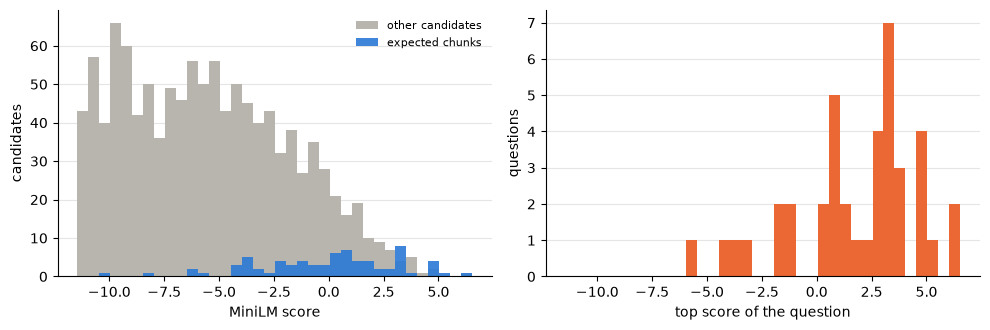

In [6]:
# Mark expected chunks in the cache
expected_items = {q.id: set().union(*ev.expected_chunks(q)) for q in questions}
cache["expected"] = [item in expected_items[i] for i, item in zip(cache["id"], cache["item"])]
# Top score per question
top_score = SCORES[:, 0]

# Create figure and shared bins
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.linspace(cache["score"].min(), cache["score"].max(), 37)
# Score distribution by expected status
axes[0].hist(cache.loc[~cache["expected"], "score"], bins=bins, color="#b7b5ae", label="other candidates")
axes[0].hist(cache.loc[cache["expected"], "score"], bins=bins, color="#2a78d6", label="expected chunks", alpha=0.9)
axes[0].set_xlabel("MiniLM score")
axes[0].set_ylabel("candidates")
axes[0].legend(frameon=False, fontsize=8)
# Top score distribution
axes[1].hist(top_score, bins=bins, color="#eb6834")
axes[1].set_xlabel("top score of the question")
axes[1].set_ylabel("questions")
# Tidy both axes
for ax in axes:
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
# Print score summary
print(f"scores range {SCORES.min():.2f} to {SCORES.max():.2f}; question top scores range "
      f"{top_score.min():.2f} to {top_score.max():.2f}")
print("expected chunks among the 30 candidates:", int(cache["expected"].sum()), "of", len(cache))
cache.groupby("expected")["score"].describe().round(2)

## Sweep the absolute cutoff

Recall and cost only change when the cutoff crosses an observed score, so the sweep uses one cutoff per gap: the
midpoints between consecutive distinct observed scores, plus one below the minimum and one above the maximum. Any
cutoff inside a gap gives exactly the same selection, and the midpoint is the least knife-edge choice.

In [7]:
# Candidate cutoffs between observed scores
observed = np.unique(SCORES)
CUTOFFS = np.concatenate([[observed[0] - 1], (observed[:-1] + observed[1:]) / 2, [observed[-1] + 1]])
# Kept counts and metrics per cutoff
N_ABS = kept_absolute(CUTOFFS)
sweep = pd.DataFrame([{"cutoff": c, **summarise(per_question(n))} for c, n in zip(CUTOFFS, N_ABS)])
# Show a sample of the sweep
print(len(CUTOFFS), "cutoffs swept")
sweep.iloc[::60].round(3)

1201 cutoffs swept


,cutoff,chunk recall,all chunks found,mean items,median items,mean tokens
0,-12.454,0.879,0.775,15.000,15.0,7961.350
60,-10.777,0.879,0.775,14.925,15.0,7931.025
120,-10.157,0.879,0.775,14.675,15.0,7818.750
180,-9.667,0.879,0.775,14.475,15.0,7720.725
240,-9.171,0.879,0.775,14.300,15.0,7620.750
300,-8.535,0.879,0.775,13.900,15.0,7408.175
360,-7.958,0.871,0.775,13.025,15.0,6907.300
420,-7.178,0.871,0.775,12.675,15.0,6722.025
480,-6.620,0.871,0.775,12.200,15.0,6452.200
540,-6.021,0.858,0.750,11.625,15.0,6155.075


### Choosing the cutoff

**Rule (primary): the cheapest cutoff that does at least as well as top 10.** Among cutoffs whose mean chunk recall
is ≥ fixed top 10's on the same questions, take the one with the fewest mean tokens passed on (ties: higher recall).

Why this rule: top 10 is the strongest fixed setting measured so far (0.846 chunk recall), and the app already pays
for reranking 30 candidates. So the useful thing a dynamic rule can do is give top-10-level recall for less prompt.
Tokens rather than item count is the cost measure because that is what the answering model is billed and limited on;
the two track each other closely here.

**Rule (secondary, reported for comparison): best recall at no more tokens than top 10.** Among cutoffs whose mean
tokens are ≤ top 10's, take the highest recall (ties: fewer tokens).

Both rules are functions of a set of questions, so cross-validation re-runs the same rule on each training fold,
including recomputing the top-10 baseline on that fold.

In [8]:
def choose(N, mask=None, rule="match top 10"):
    # Index of the chosen row of N (one row per cutoff), using only the questions in `mask`.
    mask = np.ones(len(IDS), bool) if mask is None else mask
    # Mean recall and tokens per cutoff
    rec, tok = grid_metrics(N, mask)
    if rule == "match top 10":
        ok = rec >= RECALL[mask, 10].mean() - 1e-12
        order = np.lexsort((-rec, tok))      # fewest tokens, then highest recall
    elif rule == "budget top 10":
        ok = tok <= TOKENS[mask, 10].mean() + 1e-9
        order = np.lexsort((tok, -rec))      # highest recall, then fewest tokens
    else:
        raise ValueError(rule)
    return next(i for i in order if ok[i])


# Choose a cutoff under each rule
chosen = {rule: choose(N_ABS, rule=rule) for rule in ("match top 10", "budget top 10")}
CUTOFF = CUTOFFS[chosen["match top 10"]]
# Print chosen cutoffs and metrics
for rule, i in chosen.items():
    print(f"{rule:14}: cutoff {CUTOFFS[i]:.3f} ->", {k: round(v, 3) for k, v in summarise(per_question(N_ABS[i])).items()})
# Per-question results at the chosen cutoff
dynamic_in = per_question(N_ABS[chosen["match top 10"]])

match top 10  : cutoff -3.678 -> {'chunk recall': np.float64(0.85), 'all chunks found': np.float64(0.725), 'mean items': np.float64(9.125), 'median items': np.float64(8.5), 'mean tokens': np.float64(4788.475)}
budget top 10 : cutoff -3.919 -> {'chunk recall': np.float64(0.858), 'all chunks found': np.float64(0.75), 'mean items': np.float64(9.45), 'median items': np.float64(9.5), 'mean tokens': np.float64(4971.7)}


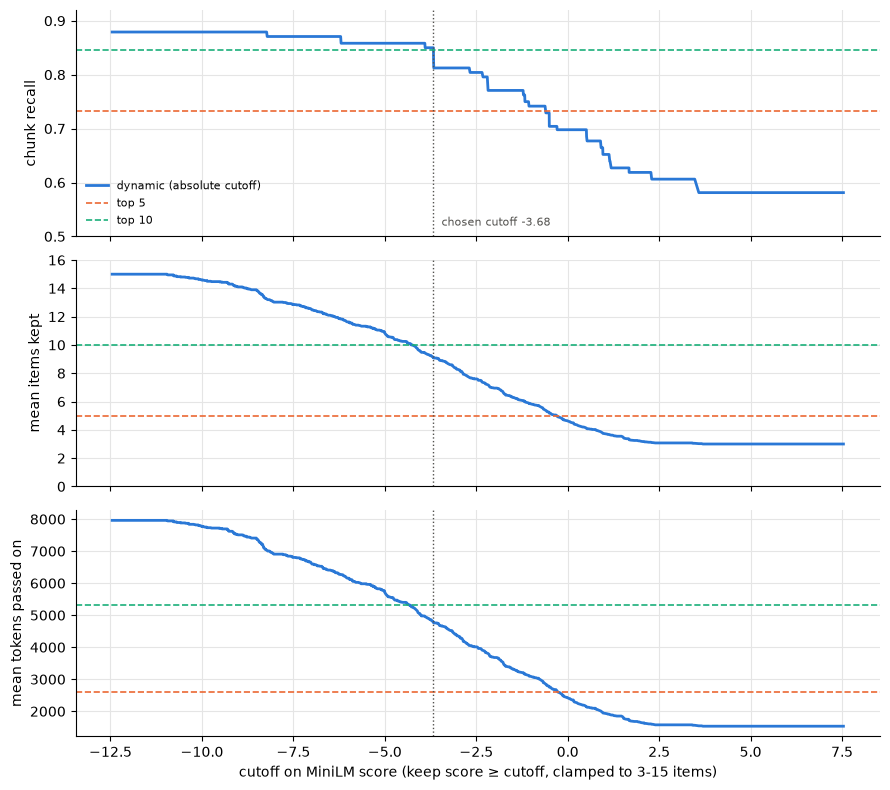

In [9]:
# Plot metrics against the cutoff
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
series = [("chunk recall", "chunk recall", (0.5, 0.92)), ("mean items", "mean items kept", (0, 16)),
          ("mean tokens", "mean tokens passed on", None)]
# Draw one panel per metric
for ax, (col, label, ylim) in zip(axes, series):
    ax.plot(sweep["cutoff"], sweep[col], color="#2a78d6", linewidth=2, label="dynamic (absolute cutoff)")
    for name, pq, color in (("top 5", top5, "#eb6834"), ("top 10", top10, "#1baf7a")):
        ax.axhline(summarise(pq)[col], color=color, linestyle="--", linewidth=1.2, label=name)
    ax.axvline(CUTOFF, color="#52514e", linewidth=1, linestyle=":")
    ax.set_ylabel(label)
    if ylim:
        ax.set_ylim(*ylim)
    ax.grid(color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
# Legend, annotation and axis label
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
axes[0].annotate(f"chosen cutoff {CUTOFF:.2f}", (CUTOFF, 0.52), xytext=(6, 0), textcoords="offset points",
                 fontsize=8, color="#52514e")
axes[-1].set_xlabel("cutoff on MiniLM score (keep score ≥ cutoff, clamped to 3-15 items)")
fig.tight_layout()

Below about −8 most questions hit the 15-item cap (median kept = 15), so recall sits at the 15-item ceiling of
0.879. Above about +2 most questions fall back to the 3-item floor. The useful range is in between. Mean tokens track
mean items closely (about 525 tokens per item), so either works as the cost measure.

## Cross-validation: how much of the gain is tuning?

- **Leave-one-out:** for each question, choose the cutoff on the other 39 with the same rule, then score that one
  question. The 40 held-out results are pooled into one table row.
- **5-fold, repeated:** 20 random 5-way splits (seed 0). Each split gives one pooled held-out result; the table shows
  the mean over splits and the range.

In [10]:
def cross_validate(N, grid, folds, rule="match top 10"):
    # Held-out n per question, and the value chosen on each fold.
    n_out, picks = np.zeros(len(IDS), int), []
    for test in folds:
        train = np.ones(len(IDS), bool)
        train[test] = False
        i = choose(N, train, rule)
        n_out[test] = N[i, test]
        picks.append(grid[i])
    return n_out, np.array(picks)


# Leave-one-out cross-validation
loo_n, loo_cutoffs = cross_validate(N_ABS, CUTOFFS, [[q] for q in range(len(IDS))])
dynamic_loo = per_question(loo_n)
print("LOO cutoffs chosen across folds:", pd.Series(loo_cutoffs).round(3).value_counts().sort_index().to_dict())

# Repeated 5-fold cross-validation
rng = np.random.default_rng(0)
kfold_rows, kfold_cutoffs = [], []
for repeat in range(20):
    folds = np.array_split(rng.permutation(len(IDS)), 5)
    n_out, picks = cross_validate(N_ABS, CUTOFFS, folds)
    kfold_rows.append(summarise(per_question(n_out)))
    kfold_cutoffs += list(picks)
# Summarise folds and print cutoff range
kfold = pd.DataFrame(kfold_rows)
print(f"5-fold cutoffs chosen: min {min(kfold_cutoffs):.2f}, median {np.median(kfold_cutoffs):.2f}, "
      f"max {max(kfold_cutoffs):.2f}")
kfold.agg(["mean", "min", "max"]).round(3)

LOO cutoffs chosen across folds: {-6.241: 1, -3.919: 1, -3.691: 1, -3.678: 37}
5-fold cutoffs chosen: min -8.23, median -3.68, max -2.34


,chunk recall,all chunks found,mean items,median items,mean tokens
mean,0.832,0.705,9.355,9.3,4922.696
min,0.812,0.675,8.800,7.5,4601.100
max,0.858,0.750,10.000,11.0,5292.925


## Final comparison

Model scoring cost is identical in every row: each rule reranks the same 30 candidates with MiniLM. Only the amount
of text passed on differs. "Dynamic, 5-fold CV" is the mean of 20 repeated splits.

In [11]:
final = pd.DataFrame({
    "top 5": summarise(top5),
    "top 10": summarise(top10),
    f"dynamic, in-sample (cutoff {CUTOFF:.2f})": summarise(dynamic_in),
    "dynamic, leave-one-out CV": summarise(dynamic_loo),
    "dynamic, 5-fold CV (20 repeats)": kfold.mean().to_dict(),
}).T
final.round({"chunk recall": 3, "all chunks found": 3, "mean items": 2, "median items": 1, "mean tokens": 0})

,chunk recall,all chunks found,mean items,median items,mean tokens
top 5,0.733,0.575,5.00,5.0,2608.0
top 10,0.846,0.750,10.00,10.0,5309.0
"dynamic, in-sample (cutoff -3.68)",0.850,0.725,9.12,8.5,4788.0
"dynamic, leave-one-out CV",0.850,0.725,9.15,8.5,4805.0
"dynamic, 5-fold CV (20 repeats)",0.832,0.705,9.36,9.3,4923.0


### Is this better than just keeping fewer?

The dynamic rule passes on about 9 items. The fair comparison is a fixed top k at the same cost, not only top 10.

In [12]:
fixed_k = pd.DataFrame([{"rule": f"top {k}", **summarise(per_question(kept_fixed(k)))} for k in range(5, 16)])
fixed_k.set_index("rule").round(3)

,chunk recall,all chunks found,mean items,median items,mean tokens
rule,,,,,
top 5,0.733,0.575,5.0,5.0,2608.250
top 6,0.788,0.650,6.0,6.0,3130.400
top 7,0.800,0.675,7.0,7.0,3639.975
top 8,0.825,0.700,8.0,8.0,4179.650
top 9,0.825,0.700,9.0,9.0,4749.375
top 10,0.846,0.750,10.0,10.0,5308.625
top 11,0.846,0.750,11.0,11.0,5825.350
top 12,0.854,0.750,12.0,12.0,6371.800
top 13,0.854,0.750,13.0,13.0,6894.750


### How sensitive is the chosen cutoff?

The rule picks the cheapest cutoff that still matches top 10, which by construction sits at the edge of a step:
just above it, at least one question loses a chunk. Nearby cutoffs:

In [13]:
nearby = CUTOFF + np.array([-1.0, -0.5, -0.25, 0.0, 0.25, 0.5, 1.0])
pd.DataFrame([{"cutoff": c, **summarise(per_question(n))} for c, n in zip(nearby, kept_absolute(nearby))]) \
    .set_index("cutoff").round(3)

,chunk recall,all chunks found,mean items,median items,mean tokens
cutoff,,,,,
-4.677956,0.858,0.750,10.375,12.0,5470.125
-4.177956,0.858,0.750,9.900,11.5,5202.350
-3.927956,0.858,0.750,9.475,9.5,4977.550
-3.677956,0.850,0.725,9.125,8.5,4788.475
-3.427956,0.812,0.675,8.875,8.0,4658.275
-3.177956,0.812,0.675,8.600,7.5,4522.375
-2.677956,0.804,0.650,7.675,6.0,4050.675


### Per-question view against top 10

Mean recall hides how few questions move. Each question is 2.5% of the score; the 95% interval is a bootstrap over
questions (10,000 resamples) of the mean difference from top 10.

In [14]:
def versus_top10(pq, name, resamples=10_000):
    # Differences from top 10
    d_rec, d_tok = pq["recall"] - top10["recall"], pq["tokens"] - top10["tokens"]
    # Bootstrap interval of the recall difference
    boot = np.random.default_rng(1).choice(d_rec.to_numpy(), (resamples, len(d_rec))).mean(1)
    # Row of counts and differences
    return {"rule": name, "better": int((d_rec > 0).sum()), "same": int((d_rec == 0).sum()),
            "worse": int((d_rec < 0).sum()), "mean recall diff": d_rec.mean(),
            "95% interval": f"{np.percentile(boot, 2.5):+.3f} to {np.percentile(boot, 97.5):+.3f}",
            "mean token diff": d_tok.mean(), "token diff %": 100 * d_tok.mean() / top10["tokens"].mean()}


# Compare each rule against top 10
pd.DataFrame([versus_top10(top5, "top 5"), versus_top10(per_question(kept_fixed(9)), "top 9"),
              versus_top10(dynamic_in, "dynamic in-sample"), versus_top10(dynamic_loo, "dynamic LOO")]) \
    .set_index("rule").round(3)

,better,same,worse,mean recall diff,95% interval,mean token diff,token diff %
rule,,,,,,,
top 5,0,32,8,-0.112,-0.196 to -0.042,-2700.375,-50.868
top 9,0,38,2,-0.021,-0.054 to +0.000,-559.250,-10.535
dynamic in-sample,2,35,3,0.004,-0.050 to +0.071,-520.150,-9.798
dynamic LOO,2,35,3,0.004,-0.050 to +0.071,-504.075,-9.495


In [15]:
# Per-question comparison table
changed = pd.DataFrame({"type": TYPES, "top 10 recall": top10["recall"].to_numpy(),
                        "dynamic n": dynamic_in["n"].to_numpy(), "dynamic recall": dynamic_in["recall"].to_numpy(),
                        "LOO n": dynamic_loo["n"].to_numpy(), "LOO recall": dynamic_loo["recall"].to_numpy(),
                        "top score": SCORES[:, 0]}, index=IDS)
# Keep questions whose recall differs from top 10
changed = changed[(changed["dynamic recall"] != changed["top 10 recall"])
                  | (changed["LOO recall"] != changed["top 10 recall"])]
changed.round(2)

,type,top 10 recall,dynamic n,dynamic recall,LOO n,LOO recall,top score
A-01,existing,0.33,15,0.67,15,0.67,2.72
A-04,existing,1.00,3,0.67,3,0.67,-1.82
A-12,multi-article,0.67,3,0.33,3,0.33,-5.61
C1-04,reworded,0.00,15,1.00,15,1.00,0.63
C1-07,multi-article,1.00,3,0.50,3,0.50,0.05


In [16]:
# Recall by type and rule
by_type = pd.DataFrame({name: pq.groupby("type")["recall"].mean()
                        for name, pq in (("top 5", top5), ("top 10", top10), ("dynamic in-sample", dynamic_in),
                                         ("dynamic LOO", dynamic_loo))})
by_type.insert(0, "questions", pd.Series(TYPES).value_counts())
# Mean items kept by type
items_by_type = pd.DataFrame({"dynamic mean items": dynamic_in.groupby("type")["n"].mean()})
by_type.join(items_by_type).round(2)

,questions,top 5,top 10,dynamic in-sample,dynamic LOO,dynamic mean items
type,,,,,,
existing,11,0.94,0.94,0.94,0.94,7.82
multi-article,12,0.61,0.71,0.64,0.64,9.50
multi-section,8,0.71,1.00,1.00,1.00,12.12
reworded,9,0.67,0.78,0.89,0.89,7.56


## Side check: a relative cutoff

Keep candidates scoring within X of the question's top score, clamped to 3–15. This adapts to questions whose scores
run high or low overall. Same sweep, same choice rule, same leave-one-out check.

In [17]:
# Margins and kept counts
gaps = np.unique(SCORES[:, :1] - SCORES)
MARGINS = np.concatenate([[-0.5], (gaps[:-1] + gaps[1:]) / 2, [gaps[-1] + 1]])
N_REL = kept_relative(MARGINS)
# Choose margin and run leave-one-out
i_rel = choose(N_REL)
rel_loo_n, rel_loo_margins = cross_validate(N_REL, MARGINS, [[q] for q in range(len(IDS))])
# Repeated 5-fold with the relative margin
rel_kfold = []
rng = np.random.default_rng(0)
for repeat in range(20):
    rel_kfold.append(summarise(per_question(
        cross_validate(N_REL, MARGINS, np.array_split(rng.permutation(len(IDS)), 5))[0])))
# Report chosen margin and LOO range
print(f"chosen margin {MARGINS[i_rel]:.3f}; LOO margins chosen: min {rel_loo_margins.min():.2f}, "
      f"max {rel_loo_margins.max():.2f}")
# Compare absolute and relative rules
pd.DataFrame({
    "top 10": summarise(top10),
    f"absolute, in-sample (cutoff {CUTOFF:.2f})": summarise(dynamic_in),
    "absolute, LOO": summarise(dynamic_loo),
    f"relative, in-sample (margin {MARGINS[i_rel]:.2f})": summarise(per_question(N_REL[i_rel])),
    "relative, LOO": summarise(per_question(rel_loo_n)),
    "relative, 5-fold CV (20 repeats)": pd.DataFrame(rel_kfold).mean().to_dict(),
}).T.round(3)

chosen margin 4.780; LOO margins chosen: min 4.67, max 6.26


,chunk recall,all chunks found,mean items,median items,mean tokens
top 10,0.846,0.750,10.000,10.00,5308.625
"absolute, in-sample (cutoff -3.68)",0.850,0.725,9.125,8.50,4788.475
"absolute, LOO",0.850,0.725,9.150,8.50,4804.550
"relative, in-sample (margin 4.78)",0.850,0.700,8.600,7.00,4597.150
"relative, LOO",0.838,0.675,8.575,7.00,4581.700
"relative, 5-fold CV (20 repeats)",0.834,0.668,8.551,7.05,4564.644


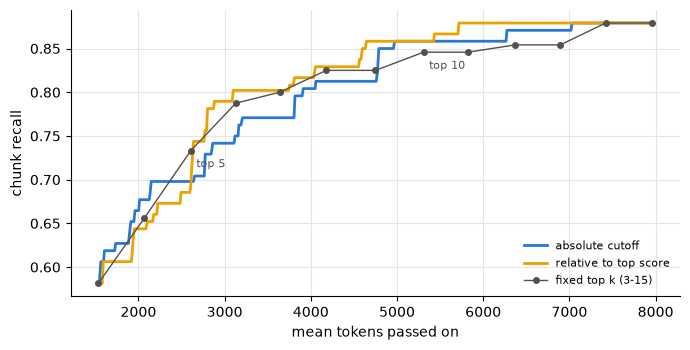

In [18]:
# Relative cutoff sweep
rel_sweep = pd.DataFrame([{"margin": m, **summarise(per_question(n))} for m, n in zip(MARGINS, N_REL)])
# Plot absolute, relative and fixed-k curves
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(sweep["mean tokens"], sweep["chunk recall"], color="#2a78d6", linewidth=2, label="absolute cutoff")
ax.plot(rel_sweep["mean tokens"], rel_sweep["chunk recall"], color="#eda100", linewidth=2, label="relative to top score")
# Fixed top k sweep
fixed_k = pd.DataFrame([{"k": k, **summarise(per_question(kept_fixed(k)))} for k in range(3, 16)])
ax.plot(fixed_k["mean tokens"], fixed_k["chunk recall"], color="#52514e", linewidth=1, marker="o", markersize=4,
        label="fixed top k (3-15)")
# Label top 5 and top 10
for k in (5, 10):
    row = fixed_k[fixed_k["k"] == k].iloc[0]
    ax.annotate(f"top {k}", (row["mean tokens"], row["chunk recall"]), xytext=(4, -12), textcoords="offset points",
                fontsize=8, color="#52514e")
# Axis labels, legend and styling
ax.set_xlabel("mean tokens passed on")
ax.set_ylabel("chunk recall")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()

The trade-off curve above puts all three families on the same axes: recall against the prompt they cost. A rule is
only worth adopting if its curve sits clearly above the fixed-k line, not just at one tuned point. Here both
in-sample curves cross the fixed-k line several times: a little above it between about 4,500 and 5,700 tokens and
below it elsewhere, and these are in-sample curves, so they are the optimistic case.

## Conclusions

**Chosen cutoff: −3.68** on MiniLM's score. The rule: the cheapest cutoff (fewest mean tokens) whose chunk recall
matches or beats fixed top 10 on the same questions.

| rule | chunk recall | all chunks found | mean items | median items | mean tokens |
|---|---|---|---|---|---|
| top 5 | 0.733 | 0.575 | 5.0 | 5 | 2,608 |
| top 10 | 0.846 | 0.750 | 10.0 | 10 | 5,309 |
| dynamic, in-sample | 0.850 | 0.725 | 9.1 | 8.5 | 4,788 |
| dynamic, leave-one-out | 0.850 | 0.725 | 9.2 | 8.5 | 4,805 |
| dynamic, 5-fold (20 repeats) | 0.832 (0.812–0.858) | 0.705 | 9.4 | 9.3 | 4,923 |

What the numbers say:

- **In-sample, the dynamic rule matches top 10 with about 10% fewer tokens:** 0.850 against 0.846 recall, at
  4,788 tokens against 5,309. But it finds every expected chunk on one fewer question (0.725 against 0.750).
- **Leave-one-out barely differs from in-sample.** 37 of the 40 folds picked the same cutoff, because dropping one
  question rarely moves the cheapest matching cutoff. So LOO is a weak check here.
- **5-fold cross-validation shows the tuning gain.** Recall drops to 0.832 on average, below top 10's 0.846, with the
  20 repeats spanning 0.812 to 0.858. Tokens rise to 4,923, about 7% below top 10. Compared with in-sample, that is
  −0.018 recall and +134 tokens.
- **It isn't better than keeping fewer items.** Fixed top 9 gives 0.825 recall at 4,749 tokens, and top 8 gives
  0.825 at 4,180. The cross-validated dynamic rule (0.832 at 4,923) lands on the fixed-k trade-off curve, not
  above it.
- **The differences come down to a handful of questions.** Against top 10, the tuned rule is better on 2 questions,
  worse on 3 and the same on 35. The 95% bootstrap interval for the mean recall difference is −0.050 to +0.071.
- **The floor of 3 causes the losses; the cap of 15 brings the gains.** All 3 questions it loses (A-04, A-12,
  C1-07) have a low top score, so few candidates pass and only 3 are kept. Both gains (A-01, C1-04) come from
  questions where 15 pass and an expected chunk sits at rank 11-15.
- **The cutoff is on a knife edge.** By construction the rule picks the edge of a step. Moving it 0.25 higher drops
  recall to 0.812; moving it 0.25 lower gives 0.858 at 4,978 tokens.
- **The rule adapts in the intended direction.** It keeps more for multi-section questions (12.1 items on average)
  and fewer for existing and reworded ones (about 7.7). It gains on reworded questions (0.89 against 0.78) and loses
  on multi-article ones (0.64 against 0.71). Each type has only 8–12 questions, so these splits are noise-sized too.
- **The relative variant (within 4.78 of the top score) isn't clearly different.** Cross-validated, it gets 0.834
  recall at 4,565 tokens with 5 folds and 0.838 with leave-one-out. That is the same picture as the absolute cutoff.

**Recommendation: don't adopt dynamic selection on this evidence.** Its only in-sample advantage is a 10% token
saving at top-10 recall, and that advantage doesn't survive cross-validation. A fixed k gives the same trade-off and
is simpler to reason about. The bigger lever is k itself: moving from top 5 to top 10 adds 0.11 recall for twice the
tokens.

Worth revisiting if:
- a held-out question set is added, since tuning and evaluating on these 40 overstates the result;
- a reranker with better-calibrated scores is used. MiniLM's scores are raw logits, and it reads only about the
  first 512 tokens of each chunk.

All rules rerank the same 30 candidates, so model scoring cost (about 2.8 s per question here) is the same for every
row.